# 3804ICT ASSIGNMENT 1: DATA MINING PROJECT PROPOSAL
## Predicting Bank Telemarketing Success Using KNN & Decision Tree
### _Griffith University, Trimester 2, 2026_

#### _Chanh Pham (S5052032) & Farah Hannah Abdurahman (S5353326)_


## A. Data Exploration

##### The following section explores the number of data samples and attributes, attribute types, and statistical information, including the five-number summary for each numerical attribute.

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("bank-additional-full.csv", delimiter=";")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


#### 1. Dataset Size and Attributes:

_The dataset dimensions were examined to confirm the no. of customer records, input attributes, and target attribute._

In [3]:
#Checking the size of the dataset
print(f"Samples: {df.shape[0]}")
print(f"Input attributes: {df.shape[1] - 1}")
print(f"Target attributes: 1")

Samples: 41188
Input attributes: 20
Target attributes: 1


In [4]:
#attribute names
print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


#### 2. Attribute Types:

_The data types of each attribute were examined before separated into two categories: numerical and categorical attributes, for further analysis._

In [5]:
#Data inspection
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [6]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical attributes:")
print(numerical_cols)

print("\nCategorical attributes:")
print(categorical_cols)

Numerical attributes:
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical attributes:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']


In [7]:
attribute_summary = pd.DataFrame({
    "Attribute": df.columns,
    "Pandas Type": df.dtypes.astype(str).values,
    "Data Type": [
        "Numerical" if pd.api.types.is_numeric_dtype(df[col])
        else "Categorical"
        for col in df.columns
    ],
    "Unique Values": [df[col].nunique() for col in df.columns]
})

attribute_summary

,Attribute,Pandas Type,Data Type,Unique Values
0,age,int64,Numerical,78
1,job,str,Categorical,12
2,marital,str,Categorical,4
3,education,str,Categorical,8
4,default,str,Categorical,3
5,housing,str,Categorical,3
6,loan,str,Categorical,3
7,contact,str,Categorical,2
8,month,str,Categorical,10
9,day_of_week,str,Categorical,5


#### 3. Numerical Attribute:

_Statistics are calculated for each numerical attribute, with its outputs including the five-number summary as required: minimum (min), first-quartile (25%), median (50%), third quartile (75%), and maximum (max)._

In [8]:
#Numerical Exploration
numerical_statistics = df[numerical_cols].describe().T

numerical_statistics

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


#### 4. Categorical Attribute:

_Categorical attributes are explored using their unique values, frequency counts, and percentage distributions to understand how the categories are distributed within the dataset._

In [9]:
#categorical exploration
def categorical_summary(dataframe, columns):
    for column in columns:
        print(f"\n{'=' * 50}")
        print(f"Attribute: {column}")
        print(f"Number of unique values: {dataframe[column].nunique()}")
        summary = pd.DataFrame({
            "Count": dataframe[column].value_counts(),
            "Percentage": dataframe[column].value_counts(normalize=True) * 100
        })
        print(summary)
categorical_summary(df, categorical_cols)


Attribute: job
Number of unique values: 12
               Count  Percentage
job                             
admin.         10422   25.303486
blue-collar     9254   22.467709
technician      6743   16.371273
services        3969    9.636302
management      2924    7.099155
retired         1720    4.175974
entrepreneur    1456    3.535010
self-employed   1421    3.450034
housemaid       1060    2.573565
unemployed      1014    2.461882
student          875    2.124405
unknown          330    0.801204

Attribute: marital
Number of unique values: 4
          Count  Percentage
marital                    
married   24928   60.522482
single    11568   28.085850
divorced   4612   11.197436
unknown      80    0.194231

Attribute: education
Number of unique values: 8
                     Count  Percentage
education                             
university.degree    12168   29.542585
high.school           9515   23.101389
basic.9y              6045   14.676605
professional.course   5243   12.729

## B. Data Visualisation

##### The following section uses different visualisation techniques to examine the distribution and characteristics of all attributes in the dataset. 

##### Histograms and boxplots are used for numerical attributes, while bar charts are used for categorical attributes.

#### 1. Numerical Attribute Visualisations:

##### 1.1 Histograms:

_Histograms are used to examine the distribution of each numerical attribute, including their spread, skewness, and concentration of values._

In [10]:
# Import matplotlib module to plot graphs:
import matplotlib.pyplot as plt

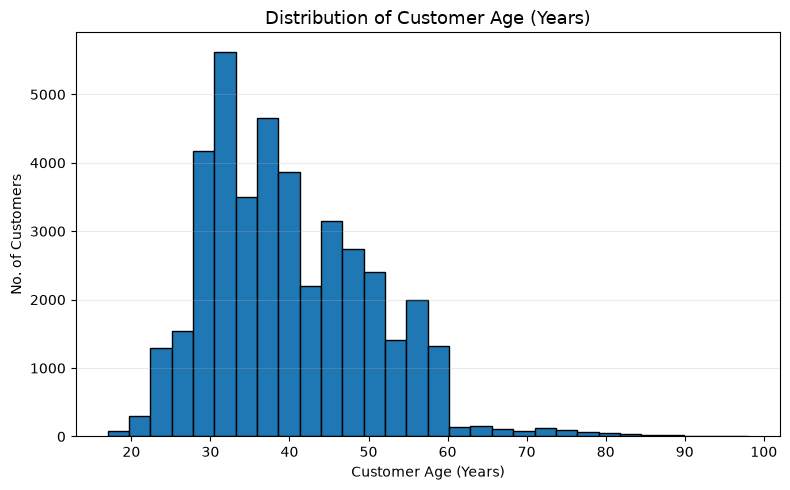

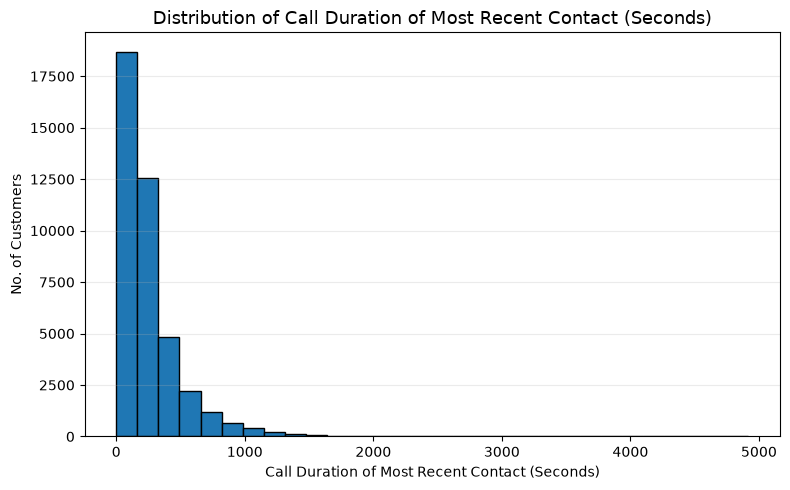

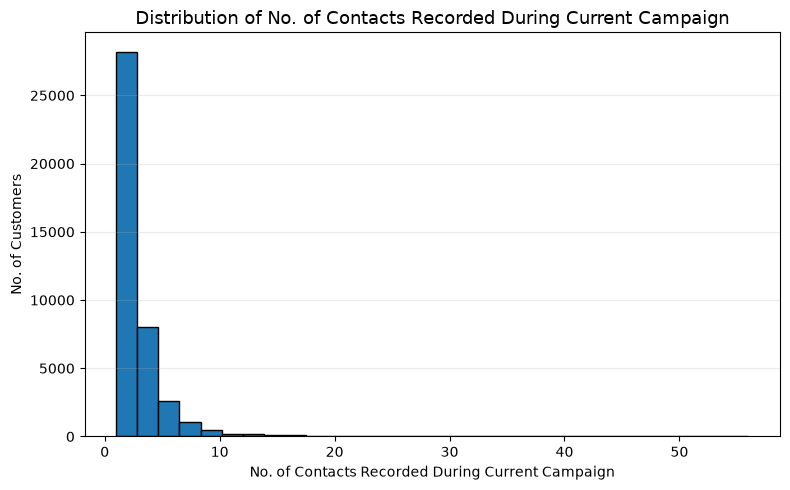

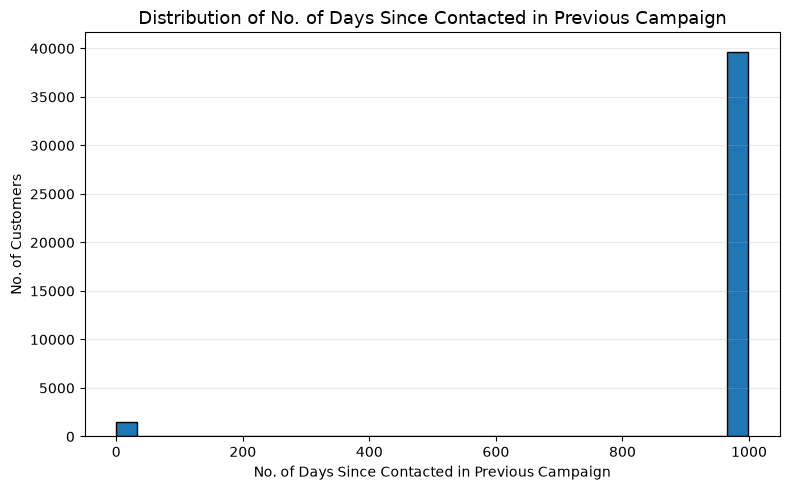

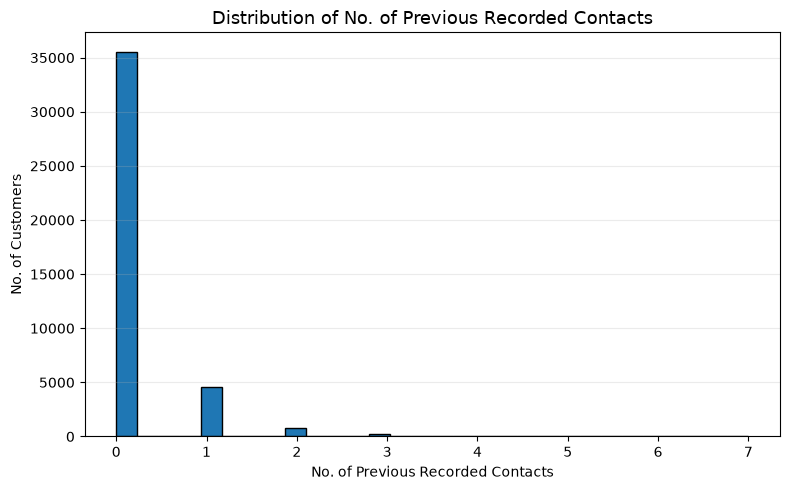

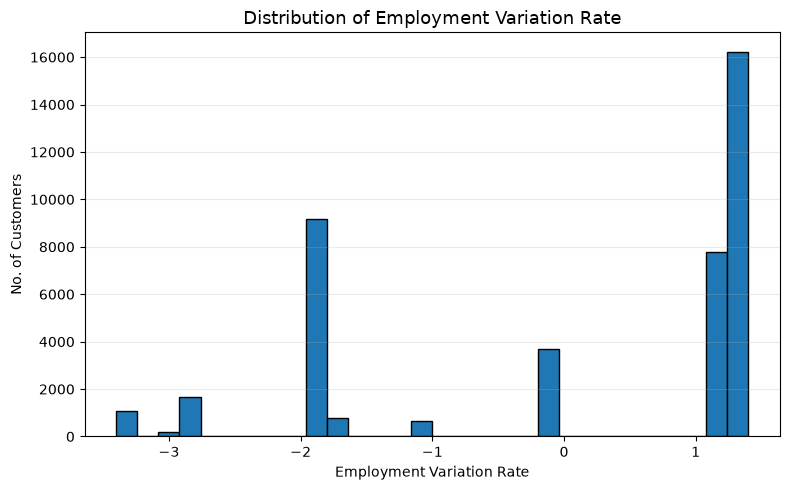

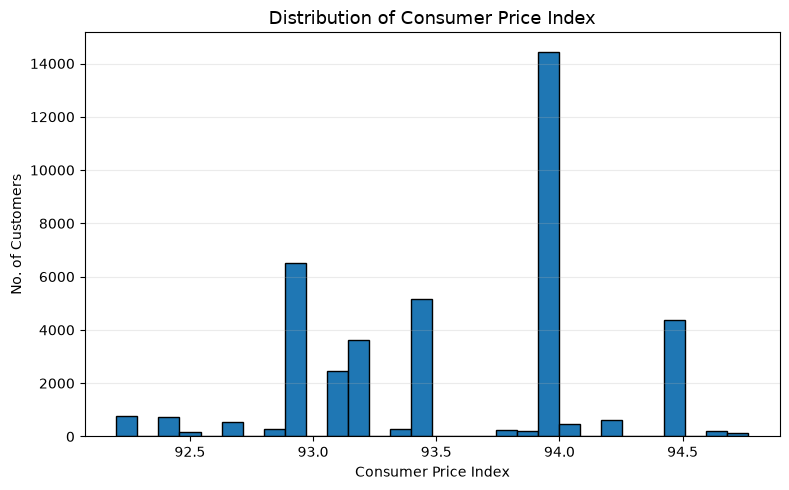

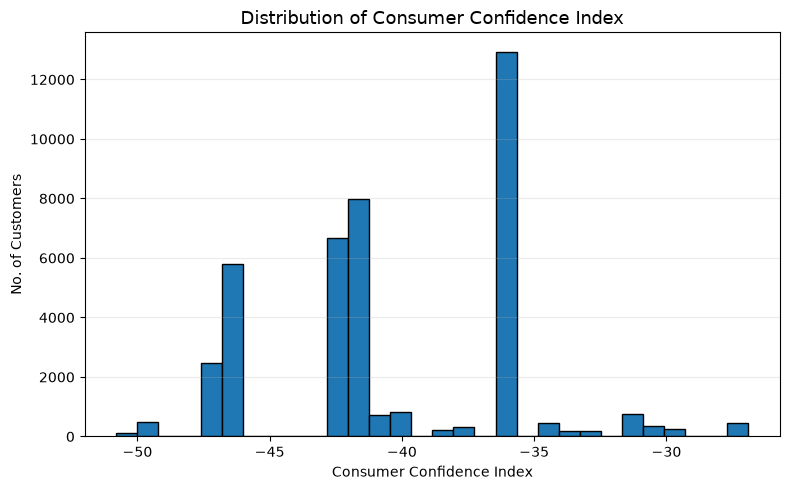

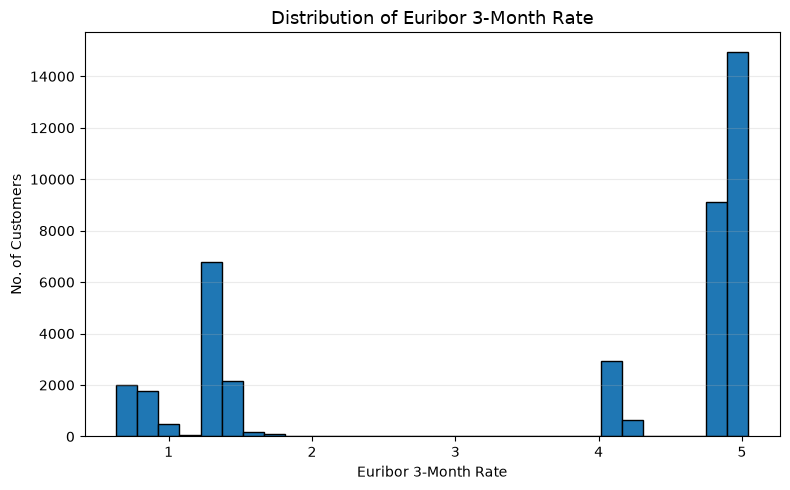

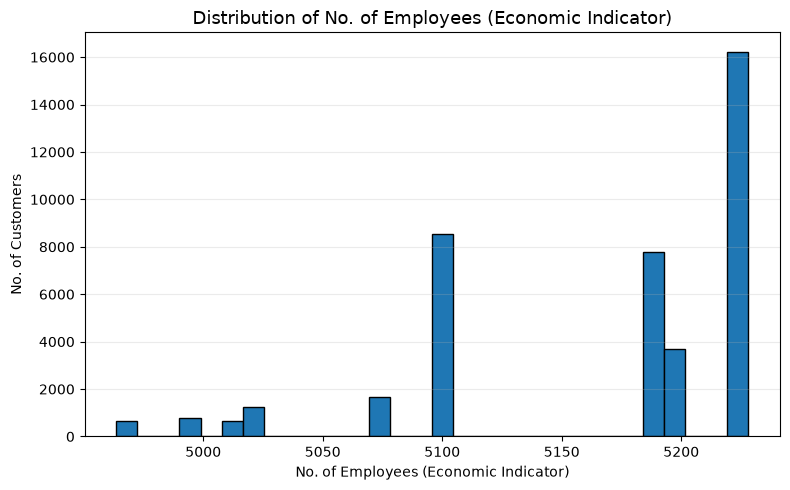

In [11]:
# Give proper labels for each numerical attributes:

attribute_labels = {
    "age": "Customer Age (Years)",
    "duration": "Call Duration of Most Recent Contact (Seconds)",
    "campaign": "No. of Contacts Recorded During Current Campaign",
    "pdays": "No. of Days Since Contacted in Previous Campaign",
    "previous": "No. of Previous Recorded Contacts",
    "emp.var.rate": "Employment Variation Rate",
    "cons.price.idx": "Consumer Price Index",
    "cons.conf.idx": "Consumer Confidence Index",
    "euribor3m": "Euribor 3-Month Rate",
    "nr.employed": "No. of Employees (Economic Indicator)"
}

# Plot a histogram graph for each numerical attribute identified above:

for column in numerical_cols:
    label = attribute_labels[column]

    plt.figure(figsize=(8, 5))
    plt.hist(df[column], bins=30, edgecolor="black")
    plt.title(f"Distribution of {label}", fontsize=13)
    plt.xlabel(label)
    plt.ylabel("No. of Customers")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

##### 1.2 Boxplots:

_Boxplots are used to examine the spread of each numerical attribute and identify potential outliers or unusual values which may require further investigation during data pre-processing._

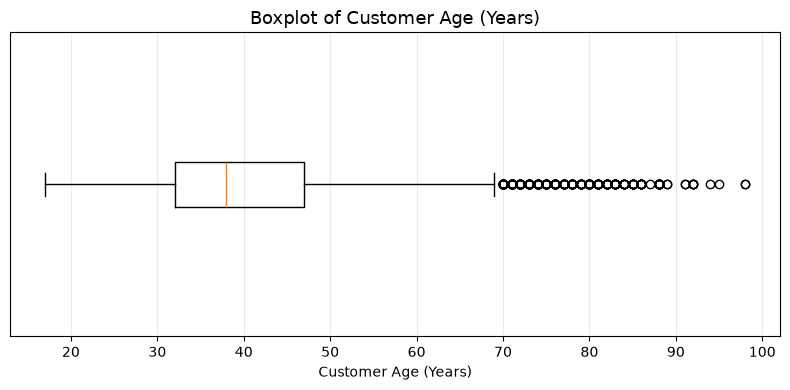

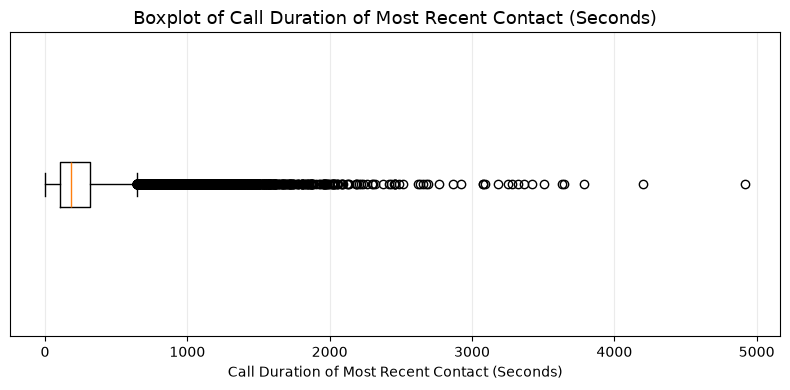

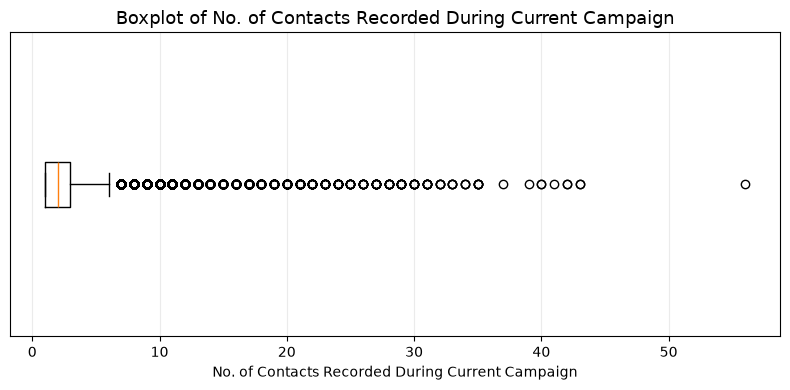

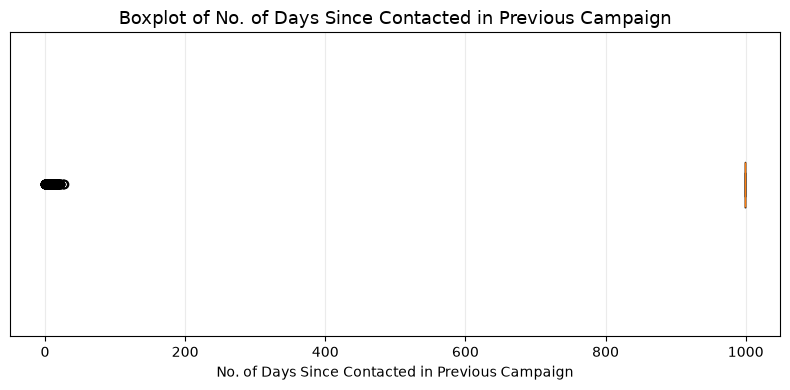

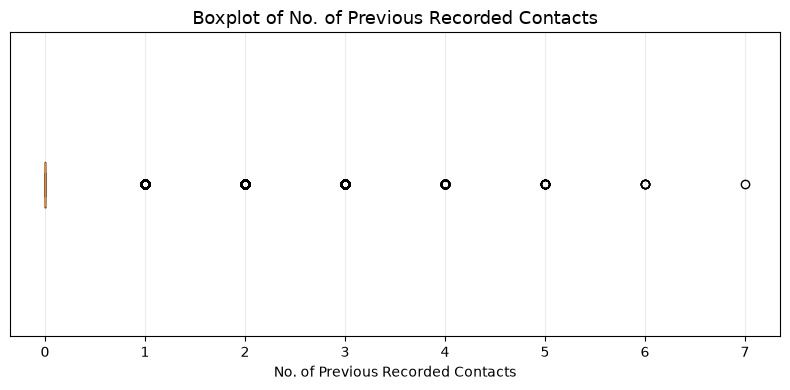

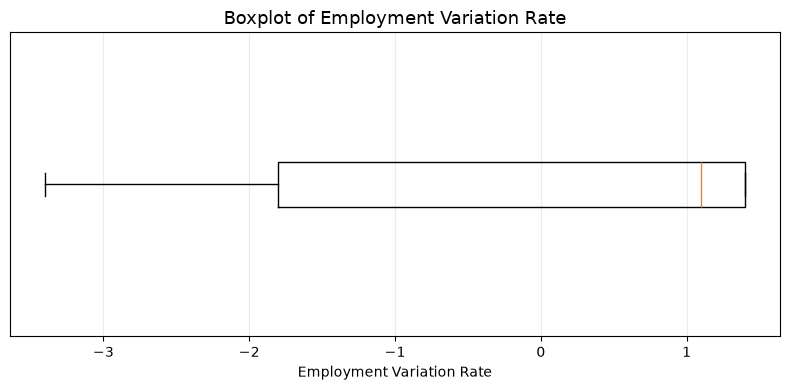

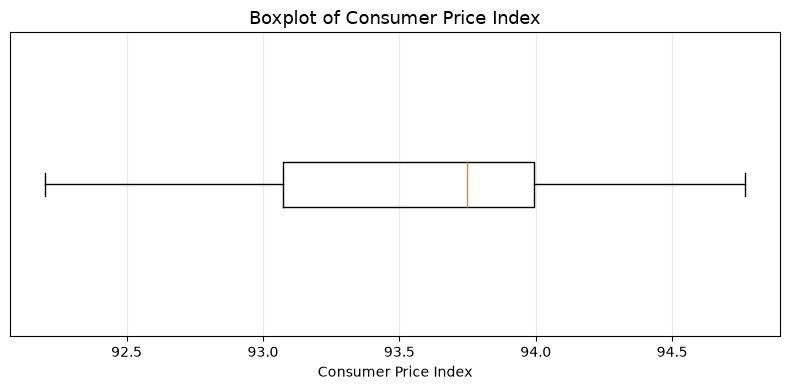

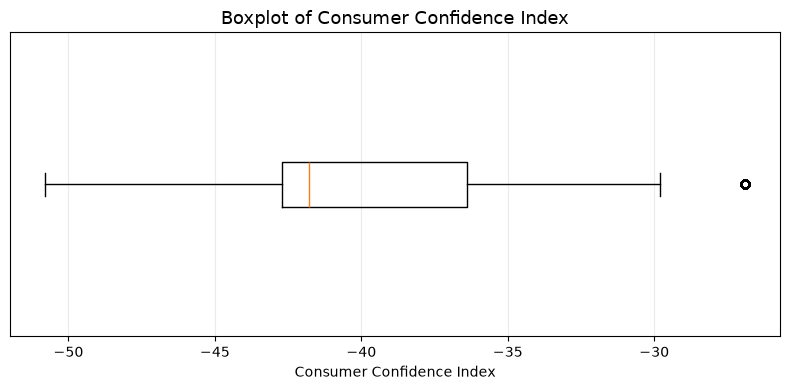

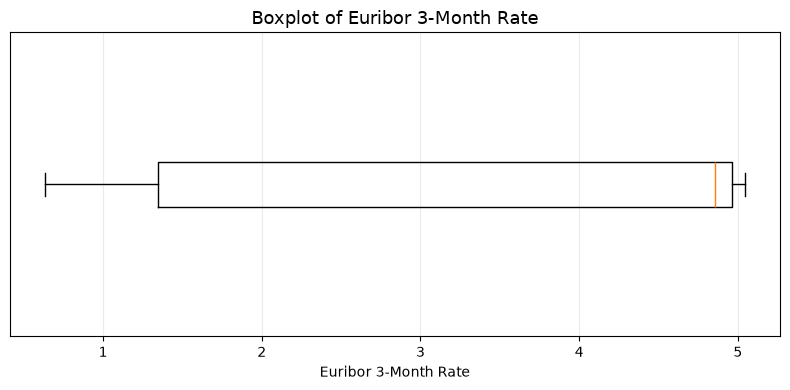

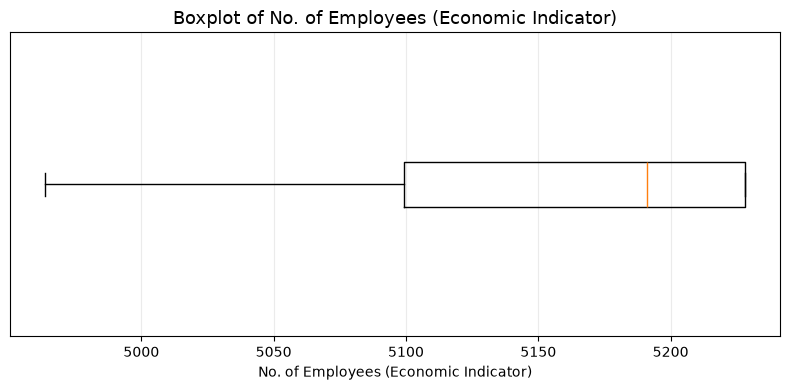

In [12]:
# Plot a boxplot for each numerical attribute identified above:

for column in numerical_cols:
    label = attribute_labels[column]

    plt.figure(figsize=(8, 4))
    plt.boxplot(df[column], orientation="horizontal")
    plt.title(f"Boxplot of {label}", fontsize=13)
    plt.xlabel(label)
    plt.yticks([])
    plt.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()

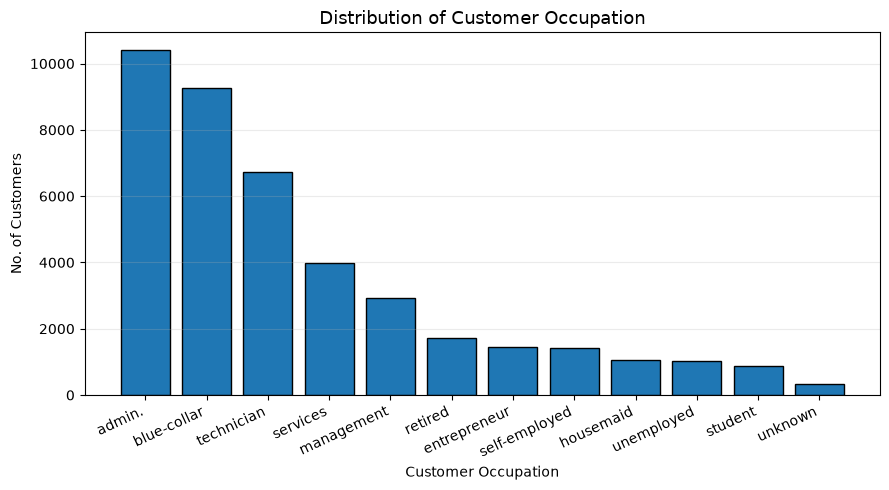

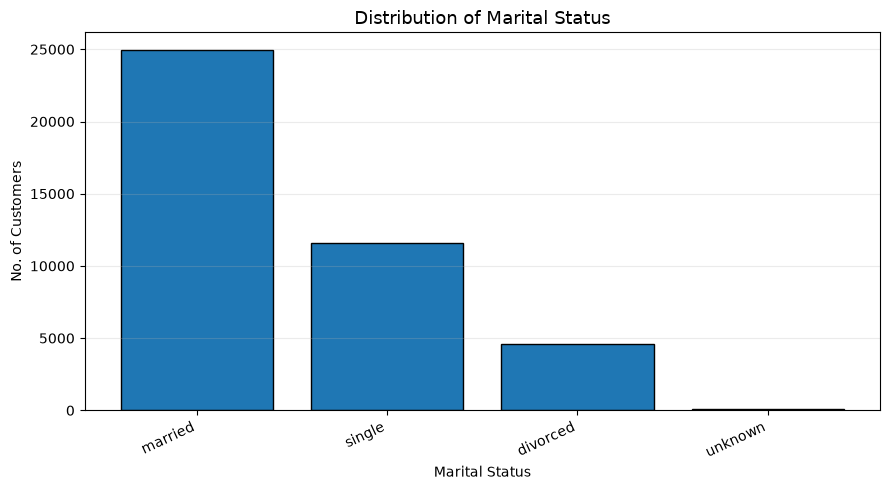

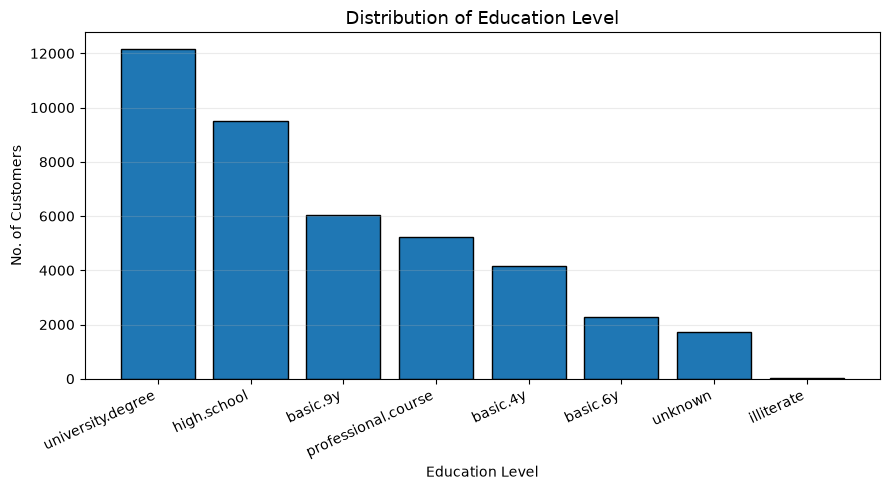

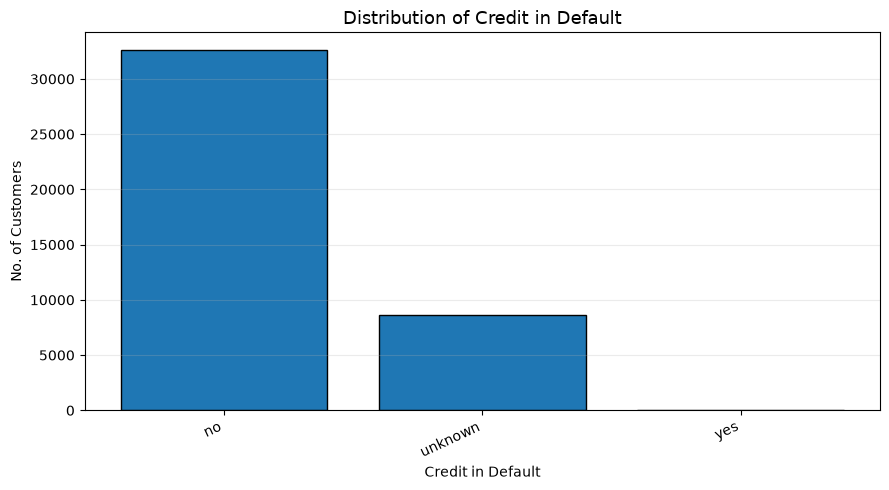

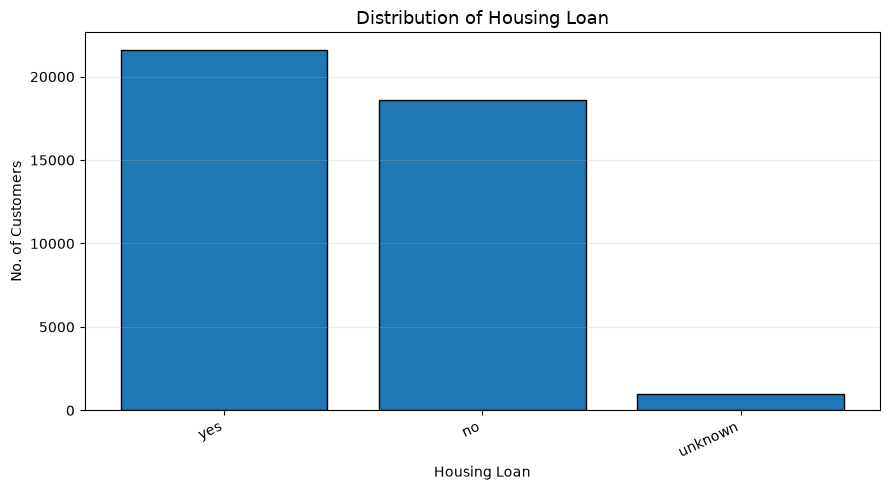

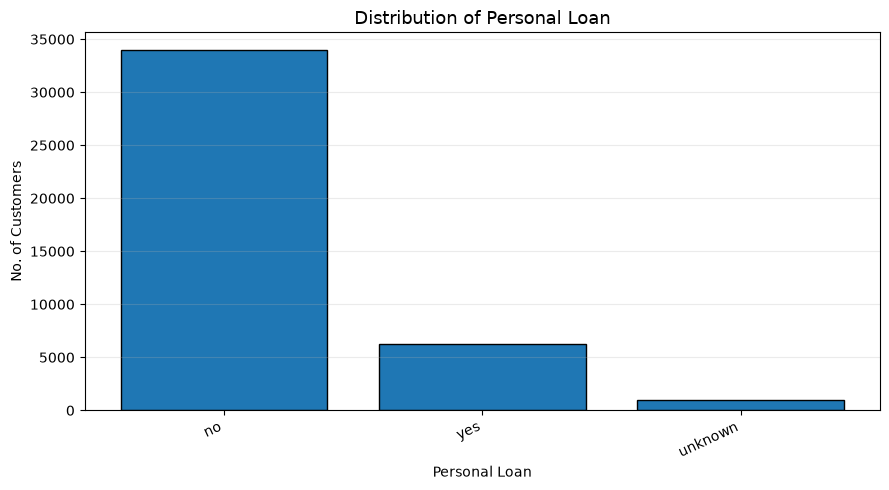

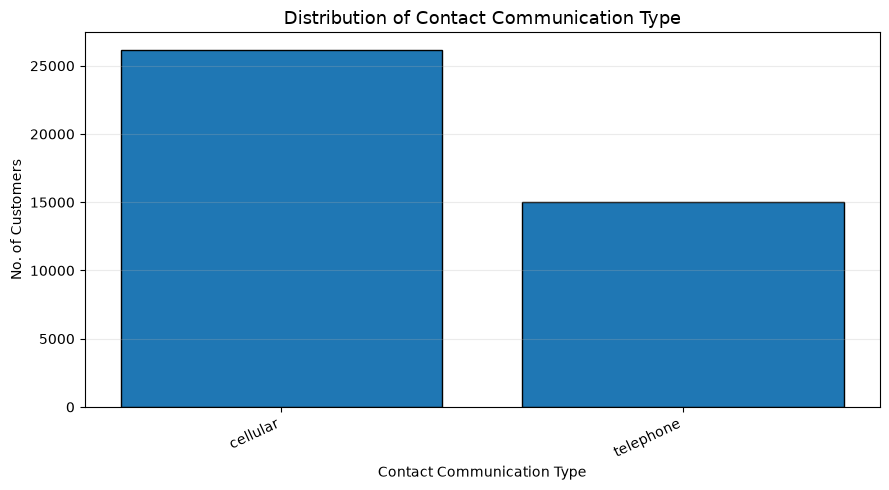

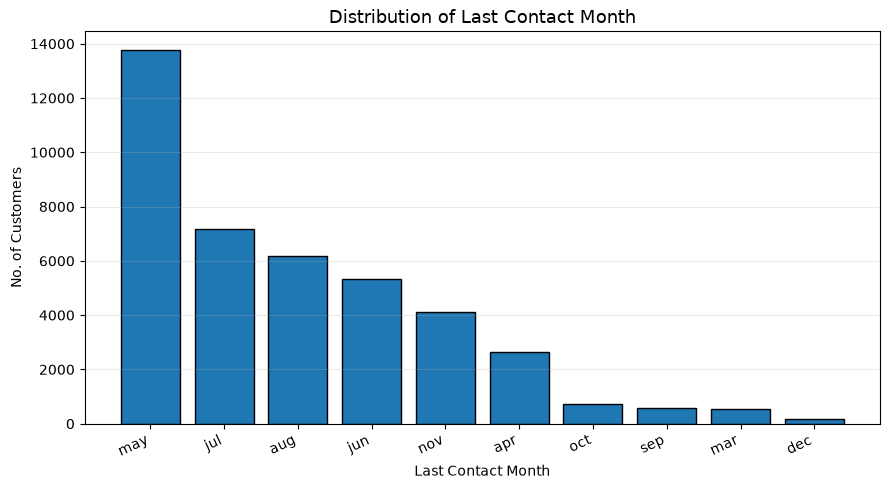

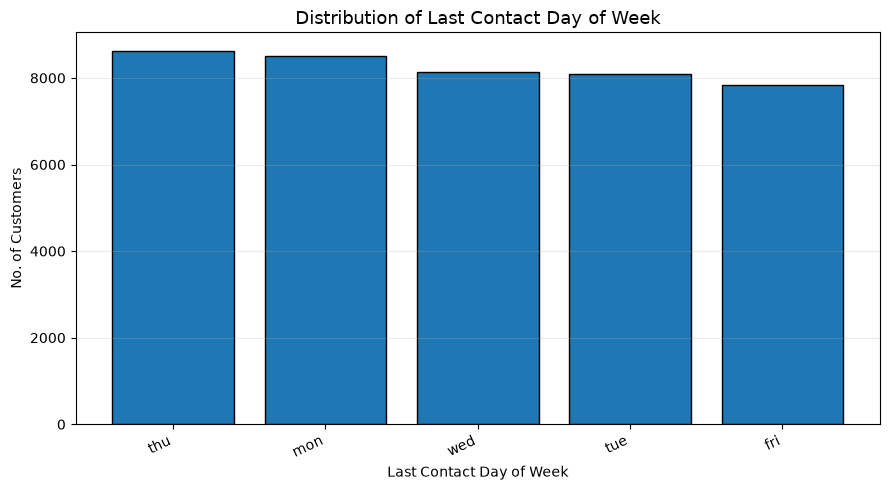

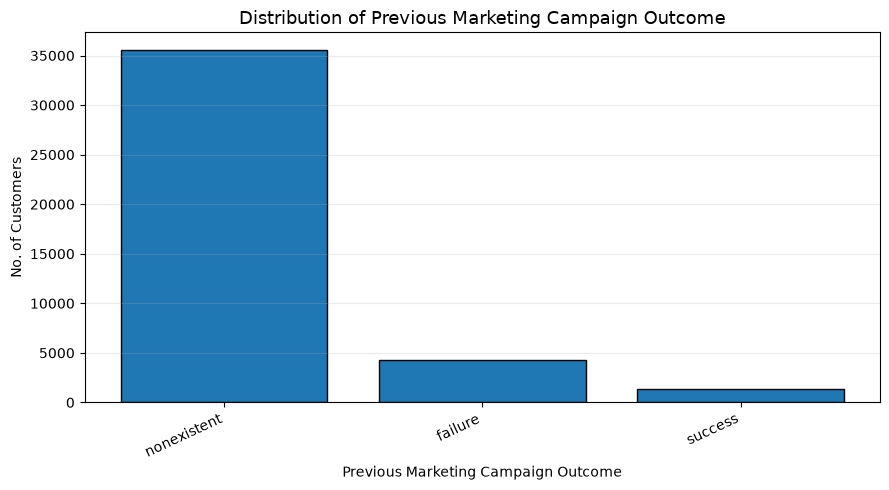

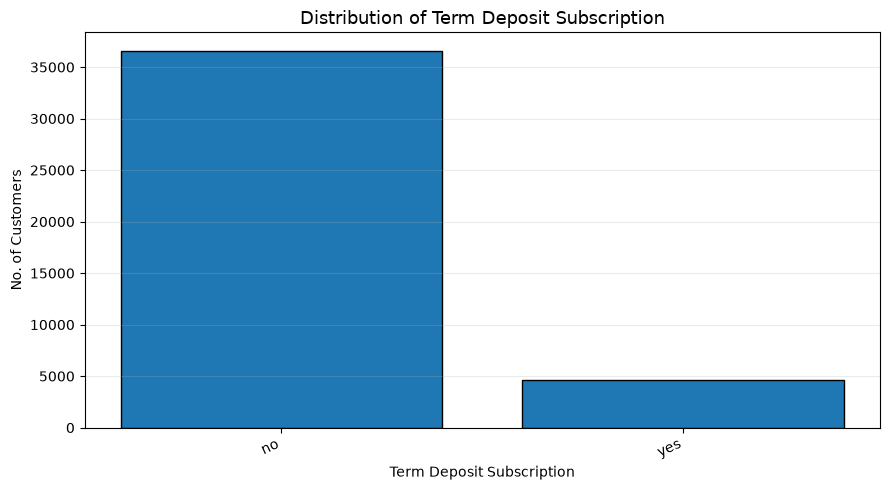

In [13]:
# Give proper labels for each categorical attribute:

categorical_labels = {
    "job": "Customer Occupation",
    "marital": "Marital Status",
    "education": "Education Level",
    "default": "Credit in Default",
    "housing": "Housing Loan",
    "loan": "Personal Loan",
    "contact": "Contact Communication Type",
    "month": "Last Contact Month",
    "day_of_week": "Last Contact Day of Week",
    "poutcome": "Previous Marketing Campaign Outcome",
    "y": "Term Deposit Subscription"
}

# Plot a bar chart for each categorical attribute identified above:

for column in categorical_cols:
    counts = df[column].value_counts()
    label = categorical_labels[column]
    
    plt.figure(figsize=(9, 5))
    plt.bar(counts.index, counts.values, edgecolor="black")
    plt.title(f"Distribution of {label}", fontsize=13)
    plt.xlabel(label)
    plt.ylabel("No. of Customers")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

## C. Data Pre-Processing and Data Quality

##### The following section investigates the dataset for potential data quality issues, including potential missing values and noisy/unusual data. 

##### Afterwards, appropriate pre-processing methods will be carried out according to the identified issues.

#### 1. Missing Values:

_The dataset is first examined for any null or missing values, across all identified attributes._

In [14]:
# Do checking in each attribute for any null or missing values:

missing_values = df.isnull().sum()
print("Missing values in each attribute:")
print(missing_values)
print("\nTotal missing values:", missing_values.sum())

Missing values in each attribute:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Total missing values: 0


#### 2. Unknown Categorical Values:

_While no null values were identified, the categorical attributes are further examined for any values recorded as "unknown", which may represent unavailable information._

In [15]:
# Check for any unknown values within all identified categorical attributes:

unknown_summary = []

for column in categorical_cols:
    unknown_count = (df[column] == "unknown").sum()

    if unknown_count > 0:
        unknown_percentage = (unknown_count / len(df)) * 100

        unknown_summary.append({
            "Attribute": column,
            "Unknown Count": unknown_count,
            "Unknown Percentage (%)": unknown_percentage
        })

unknown_summary = pd.DataFrame(unknown_summary)

unknown_summary

,Attribute,Unknown Count,Unknown Percentage (%)
0,job,330,0.801204
1,marital,80,0.194231
2,education,1731,4.202680
3,default,8597,20.872584
4,housing,990,2.403613
5,loan,990,2.403613


##### _It is observed that while no null values were identified in the dataset, several categorical attributes contain values recorded as "unknown". The highest percentage of unknown values was identified in 'default' (20.87%), followed by education (4.20%), housing (2.40%), loan (2.40%), job (0.80%), and marital (0.19%)._

##### *_These values will then be considered during data pre-processing._*


#### 3. Noisy / Unusual Data:

_The numerical attributes are then examined for any potential outliers and unusual values using the interquartile range (IQR) method. Identified values are further examined to determined whether they represent noisy data, potential outliers, or valid observations._

In [16]:
# Check for any potential outliers in each numerical attribute using the IQR method:
outlier_summary = []

for column in numerical_cols:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)
    
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]
    
    outlier_summary.append({
        "Attribute": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": len(outliers),
        "Outlier Percentage (%)": (len(outliers) / len(df)) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)
outlier_summary

,Attribute,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage (%)
0,age,9.5000,69.5000,469,1.138681
1,duration,-223.5000,644.5000,2963,7.193843
2,campaign,-2.0000,6.0000,2406,5.841507
3,pdays,999.0000,999.0000,1515,3.678256
4,previous,0.0000,0.0000,5625,13.656890
5,emp.var.rate,-6.6000,6.2000,0,0.000000
6,cons.price.idx,91.6965,95.3725,0,0.000000
7,cons.conf.idx,-52.1500,-26.9500,447,1.085268
8,euribor3m,-4.0815,10.3865,0,0.000000
9,nr.employed,4905.6000,5421.6000,0,0.000000


##### _It can be observed that while the IQR method identifies several statistical outliers, the results shown in the table above do not establish whether these observations represent noisy data, or valid but uncommon observations._

##### _The IQR method appears to be less suitable for the attributes pdays and previous, due to their unusual distributions and special values. Therefore, the identified potential outliers will be further examined before determining if data pre-processing is required._

#### 4. Examining Numerical Attributes' Ranges:

_The minimum and maximum values of each numerical attribute are examined to further investigate whether the potential outliers identified by the IQR method represent unreasonable or unusual values._

In [17]:
# Examine the minimum and maximum values of each numerical attribute:

numerical_ranges = pd.DataFrame({
    "Minimum": df[numerical_cols].min(),
    "Maximum": df[numerical_cols].max()
})

numerical_ranges

,Minimum,Maximum
age,17.000,98.000
duration,0.000,4918.000
campaign,1.000,56.000
pdays,0.000,999.000
previous,0.000,7.000
emp.var.rate,-3.400,1.400
cons.price.idx,92.201,94.767
cons.conf.idx,-50.800,-26.900
euribor3m,0.634,5.045
nr.employed,4963.600,5228.100


#### 5. Analysis of Possible Duplicate Data:

_The dataset is examined for any duplicate records which may affect data quality and reliability of the analysis._

In [18]:
# Checking for any duplicated records: 

duplicate_count = df.duplicated().sum()
duplicate_percentage = (duplicate_count / len(df)) * 100

print("No. of duplicated records:", duplicate_count)
print("Percentage of duplicated records:", duplicate_percentage)

No. of duplicated records: 12
Percentage of duplicated records: 0.02913469942701758


##### _A total of 12 duplicated records, representing approximately 0.03% of the entire dataset, were identified. While this represents only a small proportion of the dataset, duplicated data has the potential to influence the analysis. Thus, these duplicate records will be considered for removal during data pre-processing._

#### 6. Complete Proposed Data Pre-processing Methods:

_Based on the previous data investigation, the following appropriate pre-processing methods have been identified and proposed to address the identified data quality issues:_

**1. Null Values:** As no null values were identified, no treatment is required.


**2. Unknown Values in Categorical Values:** Values recorded as "unknown" will initially be kept as a separate category rather than removing the records, to avoid unnecessary data loss. This is especially important for the default attribute, as "unknown" represents 20.87% of its records. 


**3. Potential Outliers:** The potential outliers identified during the IQR method will not be automatically removed, as it is not confirmed whether these values represent incorrect or noisy data. Instead, data will be retained unless further analysis provides evidence that treatment is required. 

**4. Special Values in pday:** The value '999' in the pdays attribute will not be treated as a normal numerical outlier, as it only indicates that the customer was not previously contacted in the previous campaign. Treat it as sentinel.

**5. Duplicated Records:** The 12 duplicated records identified will be considered for removal after confirmation that they represent unnecessary duplicate, as duplicated data may potentially influence further analysis.

**6. Class Imbalance:** Account for the 88.73%/11.27% target distribution during model evaluation and potentially during training

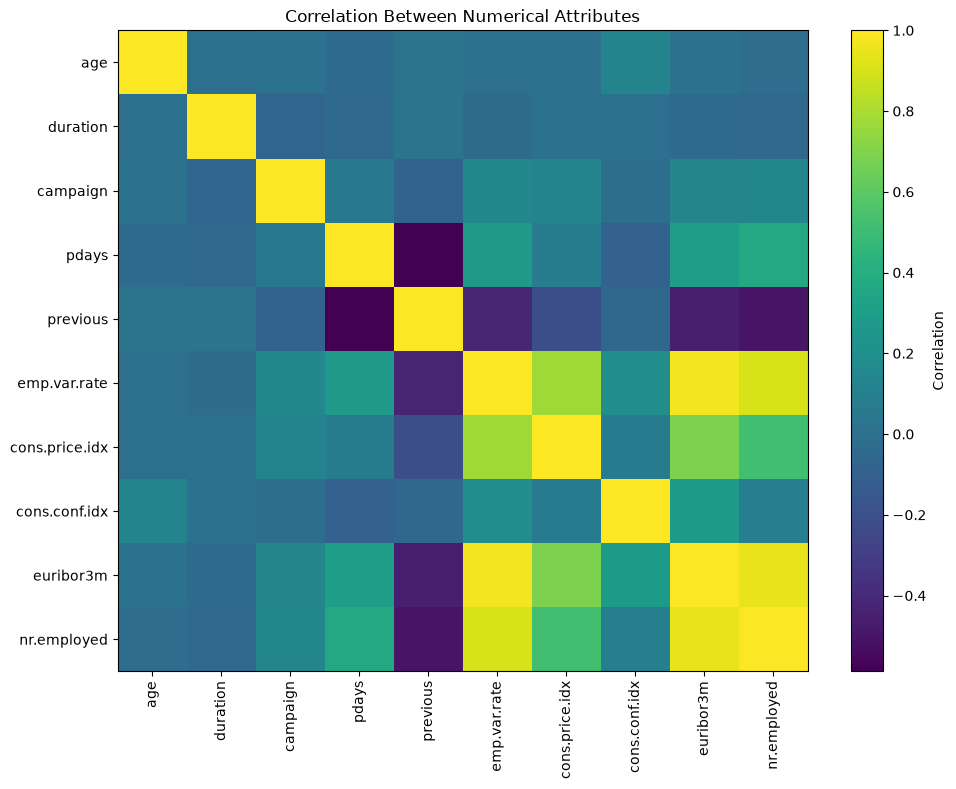

In [19]:
correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(10, 8))
plt.imshow(correlation_matrix, aspect="auto")

plt.xticks(
    range(len(numerical_cols)),
    numerical_cols,
    rotation=90
)

plt.yticks(
    range(len(numerical_cols)),
    numerical_cols
)

plt.colorbar(label="Correlation")

plt.title("Correlation Between Numerical Attributes")
plt.tight_layout()
plt.show()

In [20]:
target_summary = pd.DataFrame({
    "Count": df["y"].value_counts(),
    "Percentage (%)": df["y"].value_counts(normalize=True) * 100
})

target_summary

,Count,Percentage (%)
y,,
no,36548,88.734583
yes,4640,11.265417


In [21]:
pd.crosstab(
    df["previous"] == 0,
    df["pdays"] == 999
)

pdays,False,True
previous,,
False,1515,4110
True,0,35563


In [22]:
# Keep "unknown" as its own category
df["default"].value_counts()

default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64